<a href="https://colab.research.google.com/github/mdzameer-tech/agent-development-kit/blob/main/illicit_BLOCKchain_transaction_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# initail

In [ ]:
!ls "/content/drive/MyDrive/Elliptic project"

baseline_results.txt	   gcn_baseline_model.pt  temporal_model.pt
elliptic_txs_classes.csv   graph_export.json	  temporal_results.txt
elliptic_txs_edgelist.csv  pyg_data_object.pt
elliptic_txs_features.csv  snapshots.pt


In [ ]:
import pandas as pd

features = pd.read_csv('/content/drive/MyDrive/Elliptic project/elliptic_txs_features.csv', header=None)
classes = pd.read_csv('/content/drive/MyDrive/Elliptic project/elliptic_txs_classes.csv')
edges = pd.read_csv('/content/drive/MyDrive/Elliptic project/elliptic_txs_edgelist.csv')

print(features.shape)
print(classes.shape)
print(edges.shape)
print(classes.head())

(203769, 167)
(203769, 2)
(234355, 2)
        txId    class
0  230425980  unknown
1    5530458  unknown
2  232022460  unknown
3  232438397        2
4  230460314  unknown


In [ ]:
feature_cols = ['txId', 'time_step'] + [f'feat_{i}' for i in range(165)]
features.columns = feature_cols

In [ ]:
df = features.merge(classes, on='txId', how='left')
print("Value counts for 'class' column:")
print(df['class'].value_counts())

Value counts for 'class' column:
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


In [ ]:
# 1 = illicit -> label 1, 2 = licit -> label 0, unknown -> -1 (will be masked out)
df['label'] = df['class'].map({'1': 1, '2': 0, 'unknown': -1})

In [ ]:
print("Column names for 'edges' DataFrame:")
print(edges.columns)

Column names for 'edges' DataFrame:
Index(['txId1', 'txId2'], dtype='object')


In [ ]:
# Step 4: Build node index mapping (txId → integer index 0 to N-1)
txid_to_idx = {txid: idx for idx, txid in enumerate(df['txId'])}
df['node_idx'] = df['txId'].map(txid_to_idx)

In [ ]:
# Step 5: Build edge_index tensor
import torch

edges['src_idx'] = edges['txId1'].map(txid_to_idx)
edges['dst_idx'] = edges['txId2'].map(txid_to_idx)

edge_index = torch.tensor(edges[['src_idx', 'dst_idx']].values.T, dtype=torch.long)
print(f"Shape of edge_index: {edge_index.shape}")  # should be [2, 234355]

Shape of edge_index: torch.Size([2, 234355])


In [ ]:
# Step 6: Build feature matrix and label tensor
x = torch.tensor(df[[f'feat_{i}' for i in range(165)]].values, dtype=torch.float)
y = torch.tensor(df['label'].values, dtype=torch.long)
time_steps = torch.tensor(df['time_step'].values, dtype=torch.long)

In [ ]:
# Step 7: Build train/test masks by time step
train_mask = (time_steps <= 34) & (y != -1)
test_mask = (time_steps > 34) & (y != -1)

print(f"Number of training nodes: {train_mask.sum()}")
print(f"Number of testing nodes: {test_mask.sum()}")

Number of training nodes: 29894
Number of testing nodes: 16670


# **import 1**

In [ ]:
# Step 8: Package into PyG Data object
!pip install torch_geometric





# from torch_geometric.data import Data

# data = Data(x=x, edge_index=edge_index, y=y, train_mask=train_mask, test_mask=test_mask)
# print(data)

In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

class GCN(torch.nn.Module):
    def __init__(self, num_node_features, num_classes):
        super(GCN, self).__init__()
        torch.manual_seed(12345)
        self.conv1 = GCNConv(num_node_features, 128)
        self.conv2 = GCNConv(128, num_classes)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

# Instantiate the model
num_node_features = data.x.shape[1]
num_classes = len(data.y.unique()) - 1 # Exclude -1 (unknown class) if it's in y.unique()

# Check if -1 is in y and adjust num_classes if necessary
if -1 in data.y.unique():
    num_classes = len(data.y.unique()) - 1
else:
    num_classes = len(data.y.unique())

model = GCN(num_node_features, num_classes)
print(model)


GCN(
  (conv1): GCNConv(165, 128)
  (conv2): GCNConv(128, 2)
)


In [ ]:
import torch.optim as optim

# Define the loss function and optimizer
criterion = F.nll_loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [ ]:
# Compute class weights from training data
num_licit = (data.y[data.train_mask] == 0).sum().item()
num_illicit = (data.y[data.train_mask] == 1).sum().item()
total = num_licit + num_illicit
class_weights = torch.tensor([total/num_licit, total/num_illicit], dtype=torch.float)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

def train():
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask], weight=class_weights)
    loss.backward()
    optimizer.step()
    return loss.item()

In [ ]:
for epoch in range(1, 101):
    loss = train()
    if epoch % 10 == 0:
        print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}')

Epoch: 010, Loss: 0.3846
Epoch: 020, Loss: 0.3083
Epoch: 030, Loss: 0.2778
Epoch: 040, Loss: 0.2514
Epoch: 050, Loss: 0.2324


KeyboardInterrupt: 

# evaluate if its the same thing**

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate():
    model.eval() # Set the model to evaluation mode
    out = model(data.x, data.edge_index) # Perform a forward pass on the entire graph
    pred = out[data.test_mask].argmax(dim=1) # Get predicted labels for the test set
    true_labels = data.y[data.test_mask] # Get true labels for the test set

    # Calculate metrics
    accuracy = accuracy_score(true_labels, pred)
    precision = precision_score(true_labels, pred, average='binary') # Assuming binary classification for illicit/licit
    recall = recall_score(true_labels, pred, average='binary')
    f1 = f1_score(true_labels, pred, average='binary')

    print(f'Test Accuracy: {accuracy:.4f}')
    print(f'Test Precision: {precision:.4f}')
    print(f'Test Recall: {recall:.4f}')
    print(f'Test F1-Score: {f1:.4f}')

# Call the evaluation function
evaluate()

Test Accuracy: 0.9150
Test Precision: 0.3939
Test Recall: 0.5725
Test F1-Score: 0.4667


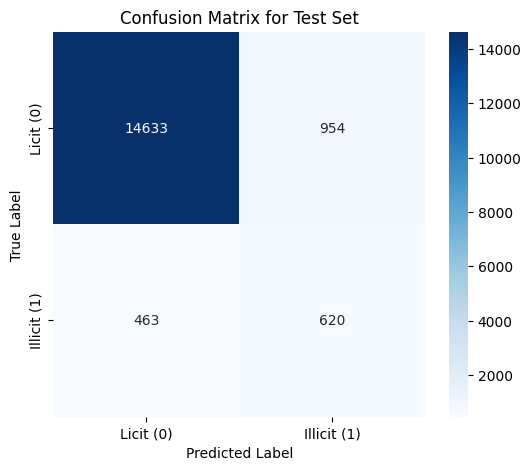

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()
out = model(data.x, data.edge_index)
pred = out[data.test_mask].argmax(dim=1)
true_labels = data.y[data.test_mask]

cm = confusion_matrix(true_labels, pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Licit (0)', 'Illicit (1)'], yticklabels=['Licit (0)', 'Illicit (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Test Set')
plt.show()

# **import 2**

In [ ]:
!pip install torch-geometric-temporal --no-deps

# save commands

In [ ]:
import torch
torch.save(model.state_dict(), '/content/drive/MyDrive/Elliptic project/gcn_baseline_model.pt')

In [ ]:
torch.save(data, '/content/drive/MyDrive/Elliptic project/pyg_data_object.pt')

In [ ]:
with open('/content/drive/MyDrive/Elliptic project/baseline_results.txt', 'w') as f:
    f.write("GCN Baseline Results:\n")
    f.write("Test Accuracy: 0.9150\n")
    f.write("Test Precision: 0.3939\n")
    f.write("Test Recall: 0.5725\n")
    f.write("Test F1-Score: 0.4667\n")
    f.write("Confusion Matrix: TN=14633, FP=954, FN=463, TP=620\n")

# **IMPORT FOR RESTART**

In [2]:
import torch
print(torch.__version__)

2.11.0+cu130


In [3]:
!pip install torch_geometric
!pip install torch-geometric-temporal --no-deps

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 10.4 MB/s  0:00:00


In [4]:
import torch
data = torch.load('/content/drive/MyDrive/Elliptic project/pyg_data_object.pt', weights_only=False)
print(data)  # sanity check — should print the same shapes as before

Data(x=[203769, 165], edge_index=[2, 234355], y=[203769], train_mask=[203769], test_mask=[203769])


In [5]:
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

In [6]:
class GCN(torch.nn.Module):
    def __init__(self, num_node_features, num_classes):
        super(GCN, self).__init__()
        torch.manual_seed(12345)
        self.conv1 = GCNConv(num_node_features, 128)
        self.conv2 = GCNConv(128, num_classes)
    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

model = GCN(data.x.shape[1], 2)
model.load_state_dict(torch.load('/content/drive/MyDrive/Elliptic project/gcn_baseline_model.pt'))

<All keys matched successfully>

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate():
    model.eval() # Set the model to evaluation mode
    out = model(data.x, data.edge_index) # Perform a forward pass on the entire graph
    pred = out[data.test_mask].argmax(dim=1) # Get predicted labels for the test set
    true_labels = data.y[data.test_mask] # Get true labels for the test set

    # Calculate metrics
    accuracy = accuracy_score(true_labels, pred)
    precision = precision_score(true_labels, pred, average='binary') # Assuming binary classification for illicit/licit
    recall = recall_score(true_labels, pred, average='binary')
    f1 = f1_score(true_labels, pred, average='binary')

    print(f'Test Accuracy: {accuracy:.4f}')
    print(f'Test Precision: {precision:.4f}')
    print(f'Test Recall: {recall:.4f}')
    print(f'Test F1-Score: {f1:.4f}')

# Call the evaluation function
evaluate()

Test Accuracy: 0.9150
Test Precision: 0.3939
Test Recall: 0.5725
Test F1-Score: 0.4667


# 'import complete'

Good choice. Here's the manual EvolveGCN-style implementation.

Core idea: instead of a GCN with fixed weight matrices, we update the weight matrix at each time step using a GRU, then apply that evolved weight as a regular graph convolution. This is essentially EvolveGCN-O's approach, simplified.

Step 1: Build per-timestep snapshots from your existing data object


# step 1

In [8]:
import pandas as pd

features_time = pd.read_csv('/content/drive/MyDrive/Elliptic project/elliptic_txs_features.csv', header=None, usecols=[0, 1])
features_time.columns = ['txId', 'time_step']

# Rebuild the same txid_to_idx mapping (must match the same order used originally)
# Since node order in `data.x` was based on df's original row order, and df came directly from features (before merge reordered anything),
# reloading fresh features CSV in the same row order gives us the same alignment
time_steps = torch.tensor(features_time['time_step'].values, dtype=torch.long)

print(time_steps.shape)  # should be [203769]

torch.Size([203769])


In [9]:
check_train = ((time_steps <= 34) & (data.y != -1)).sum()
check_test = ((time_steps > 34) & (data.y != -1)).sum()
print(check_train, check_test)  # should match: 29894, 16670

tensor(29894) tensor(16670)


In [10]:
# Build a list of (x, edge_index, y, mask) per time step
snapshots = []
time_steps_tensor = data.time_step if hasattr(data, 'time_step') else time_steps  # use your earlier time_steps tensor

for t in range(1, 50):  # time steps 1 to 49
    node_mask = (time_steps == t)
    node_indices = node_mask.nonzero(as_tuple=True)[0]

    if node_indices.numel() == 0:
        continue

    # Build a mapping from global node index to local (per-snapshot) index
    global_to_local = {g.item(): i for i, g in enumerate(node_indices)}

    # Filter edges where both endpoints are in this time step
    src, dst = data.edge_index
    edge_mask = node_mask[src] & node_mask[dst]
    local_edges = data.edge_index[:, edge_mask]
    local_src = torch.tensor([global_to_local[s.item()] for s in local_edges[0]], dtype=torch.long)
    local_dst = torch.tensor([global_to_local[d.item()] for d in local_edges[1]], dtype=torch.long)
    local_edge_index = torch.stack([local_src, local_dst])

    snapshots.append({
        'x': data.x[node_indices],
        'edge_index': local_edge_index,
        'y': data.y[node_indices],
        'global_idx': node_indices
    })

print(f"Built {len(snapshots)} snapshots")
print(snapshots[0]['x'].shape, snapshots[0]['edge_index'].shape)

Built 49 snapshots
torch.Size([7880, 165]) torch.Size([2, 9164])


In [11]:
check_train = sum((s['y'] != -1).sum().item() for i, s in enumerate(snapshots) if (i+1) <= 34)
check_test = sum((s['y'] != -1).sum().item() for i, s in enumerate(snapshots) if (i+1) > 34)
print(check_train, check_test)  # should roughly match 29894, 16670 from before

29894 16670


In [12]:
train_snapshots = snapshots[:34]   # time steps 1–34
test_snapshots = snapshots[34:]    # time steps 35–49

print(len(train_snapshots), len(test_snapshots))  # should print 34, 15

34 15


# step 2   V2

In [14]:
import torch.nn as nn
# ===== EvolveGCN v2 — with persistent hidden state across time steps =====

class EvolveGCNLayerV2(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.weight = nn.Parameter(torch.empty(in_channels, out_channels))
        nn.init.xavier_uniform_(self.weight)
        self.gru = nn.GRU(input_size=out_channels, hidden_size=out_channels, batch_first=True)
        self.current_weight = None
        self.hidden_state = None  # persists across time steps now

    def reset_hidden(self):
        # Only called once per FULL pass over all time steps (start of an epoch)
        self.current_weight = self.weight.clone()
        self.hidden_state = None

    def evolve_weight(self):
        seq = self.current_weight.unsqueeze(0)
        evolved_seq, h_n = self.gru(seq, self.hidden_state)  # feed in memory from last time step
        self.hidden_state = h_n  # carry forward to next time step
        self.current_weight = evolved_seq.squeeze(0)
        return self.current_weight

    def forward(self, x, edge_index):
        W = self.evolve_weight()
        N = x.size(0)
        self_loops = torch.arange(N, device=x.device)
        row = torch.cat([edge_index[0], self_loops])
        col = torch.cat([edge_index[1], self_loops])
        out = torch.zeros_like(x)
        out.index_add_(0, row, x[col])
        deg = torch.bincount(row, minlength=N).clamp(min=1).unsqueeze(1).float()
        out = out / deg
        out = out @ W
        return out


class EvolveGCNModelV2(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.3):
        super().__init__()
        self.layer1 = EvolveGCNLayerV2(in_channels, hidden_channels)
        self.layer2 = EvolveGCNLayerV2(hidden_channels, out_channels)
        self.dropout = dropout

    def reset(self):
        self.layer1.reset_hidden()
        self.layer2.reset_hidden()

    def forward(self, x, edge_index):
        x = self.layer1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.layer2(x, edge_index)
        return F.log_softmax(x, dim=1)


# Training loop — note: hidden_state must NOT be detached every snapshot now,
# only the weight (otherwise gradient graph would explode across all 34 steps, same crash as before)
num_licit = (data.y[data.train_mask] == 0).sum().item()
num_illicit = (data.y[data.train_mask] == 1).sum().item()
total = num_licit + num_illicit
class_weights = torch.tensor([total/num_licit, total/num_illicit], dtype=torch.float)

temporal_model_v2 = EvolveGCNModelV2(in_channels=165, hidden_channels=128, out_channels=2, dropout=0.3)
optimizer_temp_v2 = torch.optim.Adam(temporal_model_v2.parameters(), lr=0.005, weight_decay=5e-4)

def train_epoch_v2():
    temporal_model_v2.train()
    temporal_model_v2.reset()
    total_loss = 0
    all_preds, all_true = [], []
    for snap in train_snapshots:
        optimizer_temp_v2.zero_grad()
        out = temporal_model_v2(snap['x'], snap['edge_index'])
        mask = snap['y'] != -1
        if mask.sum() == 0:
            continue
        loss = F.nll_loss(out[mask], snap['y'][mask], weight=class_weights)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(temporal_model_v2.parameters(), max_norm=5.0)
        optimizer_temp_v2.step()
        total_loss += loss.item()

        all_preds.append(out[mask].argmax(dim=1).detach())
        all_true.append(snap['y'][mask])

        # detach weight AND hidden state so gradient graph doesn't accumulate across all 34 steps
        temporal_model_v2.layer1.current_weight = temporal_model_v2.layer1.current_weight.detach()
        temporal_model_v2.layer1.hidden_state = temporal_model_v2.layer1.hidden_state.detach()
        temporal_model_v2.layer2.current_weight = temporal_model_v2.layer2.current_weight.detach()
        temporal_model_v2.layer2.hidden_state = temporal_model_v2.layer2.hidden_state.detach()

    train_f1 = f1_score(torch.cat(all_true).numpy(), torch.cat(all_preds).numpy(),
                         average='binary', zero_division=0)
    return total_loss / len(train_snapshots), train_f1

for epoch in range(1, 51):
    loss, train_f1 = train_epoch_v2()
    if epoch % 5 == 0:
        print(f'Epoch {epoch}, Avg Loss: {loss:.4f}, Train F1 (illicit): {train_f1:.4f}')

Epoch 5, Avg Loss: 0.6983, Train F1 (illicit): 0.0224
Epoch 10, Avg Loss: 0.6850, Train F1 (illicit): 0.0071
Epoch 15, Avg Loss: 0.6750, Train F1 (illicit): 0.0078
Epoch 20, Avg Loss: 0.5973, Train F1 (illicit): 0.0045
Epoch 25, Avg Loss: 0.5882, Train F1 (illicit): 0.0006
Epoch 30, Avg Loss: 0.6117, Train F1 (illicit): 0.1388
Epoch 35, Avg Loss: 0.5699, Train F1 (illicit): 0.0278
Epoch 40, Avg Loss: 0.5631, Train F1 (illicit): 0.0034
Epoch 45, Avg Loss: 0.5654, Train F1 (illicit): 0.1023
Epoch 50, Avg Loss: 0.5703, Train F1 (illicit): 0.0284


#step 3

In [15]:
#not needed@!!!!!!!!!!!!!


class EvolveGCNModel(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.3):
        super().__init__()
        self.layer1 = EvolveGCNLayerV2(in_channels, hidden_channels)
        self.layer2 = EvolveGCNLayerV2(hidden_channels, out_channels)
        self.dropout = dropout

    def reset(self):
        self.layer1.reset_hidden()
        self.layer2.reset_hidden()

    def forward(self, x, edge_index):
        x = self.layer1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.layer2(x, edge_index)
        return F.log_softmax(x, dim=1)

idk


In [21]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, precision_recall_curve)


# **after 2-3  save "note" told**

In [16]:
   P = '/content/drive/MyDrive/Elliptic project/'
   snapshots = torch.load(P+'snapshots.pt', weights_only=False)
   train_snapshots, test_snapshots = snapshots[:34], snapshots[34:]
   temporal_model = EvolveGCNModel(165, 128, 2, dropout=0.3)
   temporal_model.load_state_dict(torch.load(P+'temporal_model.pt'))

<All keys matched successfully>

#step 4

In [20]:
from sklearn.metrics import f1_score

# Reuse the same class_weights from your baseline
num_licit = (data.y[data.train_mask] == 0).sum().item()
num_illicit = (data.y[data.train_mask] == 1).sum().item()
total = num_licit + num_illicit
class_weights = torch.tensor([total/num_licit, total/num_illicit], dtype=torch.float)

temporal_model = EvolveGCNModel(in_channels=165, hidden_channels=128, out_channels=2, dropout=0.3)
optimizer_temp = torch.optim.Adam(temporal_model.parameters(), lr=0.005, weight_decay=5e-4)

def train_epoch():
    temporal_model.train()
    temporal_model.reset()
    total_loss = 0
    all_preds, all_true = [], []
    for snap in train_snapshots:
        optimizer_temp.zero_grad()
        out = temporal_model(snap['x'], snap['edge_index'])
        mask = snap['y'] != -1
        if mask.sum() == 0:
            continue
        loss = F.nll_loss(out[mask], snap['y'][mask], weight=class_weights)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(temporal_model.parameters(), max_norm=5.0)
        optimizer_temp.step()
        total_loss += loss.item()

        all_preds.append(out[mask].argmax(dim=1).detach())
        all_true.append(snap['y'][mask])

        temporal_model.layer1.current_weight = temporal_model.layer1.current_weight.detach()
        temporal_model.layer2.current_weight = temporal_model.layer2.current_weight.detach()

    train_f1 = f1_score(torch.cat(all_true).numpy(), torch.cat(all_preds).numpy(),
                         average='binary', zero_division=0)
    return total_loss / len(train_snapshots), train_f1

for epoch in range(1, 51):
    loss, train_f1 = train_epoch()
    if epoch % 5 == 0:
        print(f'Epoch {epoch}, Avg Loss: {loss:.4f}, Train F1 (illicit): {train_f1:.4f}')

RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after they have already been freed). Saved intermediate values of the graph are freed when you call .backward() or autograd.grad(). Specify retain_graph=True if you need to backward through the graph a second time or if you need to access saved tensors after calling backward.

# evaluation

In [ ]:
import numpy as np

def evaluate_temporal():
    temporal_model.eval()
    temporal_model.reset()

    with torch.no_grad():
        for snap in train_snapshots:
            _ = temporal_model(snap['x'], snap['edge_index'])

    all_preds, all_true = [], []
    per_step = []

    with torch.no_grad():
        for i, snap in enumerate(test_snapshots):
            mask = snap['y'] != -1
            if mask.sum() == 0:
                continue
            out = temporal_model(snap['x'], snap['edge_index'])
            pred = out[mask].argmax(dim=1)
            true = snap['y'][mask]
            all_preds.append(pred)
            all_true.append(true)

            f1_t = f1_score(true.numpy(), pred.numpy(), average='binary', zero_division=0)
            per_step.append({'time_step': 35 + i, 'f1': f1_t, 'n': mask.sum().item()})

    all_preds = torch.cat(all_preds)
    all_true = torch.cat(all_true)

    print("Predicted class counts:", np.bincount(all_preds.numpy(), minlength=2))
    print("True class counts:     ", np.bincount(all_true.numpy(), minlength=2))

    print(f'Temporal Test Accuracy:  {accuracy_score(all_true, all_preds):.4f}')
    print(f'Temporal Test Precision: {precision_score(all_true, all_preds, average="binary", zero_division=0):.4f}')
    print(f'Temporal Test Recall:    {recall_score(all_true, all_preds, average="binary", zero_division=0):.4f}')
    print(f'Temporal Test F1-Score:  {f1_score(all_true, all_preds, average="binary", zero_division=0):.4f}')

    return per_step

temporal_per_step = evaluate_temporal()

Predicted class counts: [16670     0]
True class counts:      [15587  1083]
Temporal Test Accuracy:  0.9350
Temporal Test Precision: 0.0000
Temporal Test Recall:    0.0000
Temporal Test F1-Score:  0.0000


In [ ]:
def per_step_f1_baseline():
    model.eval()
    with torch.no_grad():
        out = model(data.x, data.edge_index)
        pred_all = out.argmax(dim=1)

    results = []
    for t in range(35, 50):
        step_mask = (time_steps == t) & (data.y != -1)
        if step_mask.sum() == 0:
            continue
        f1_t = f1_score(data.y[step_mask].numpy(), pred_all[step_mask].numpy(),
                         average='binary', zero_division=0)
        results.append({'time_step': t, 'f1': f1_t, 'n': step_mask.sum().item()})
    return results

baseline_per_step = per_step_f1_baseline()

import matplotlib.pyplot as plt
b_x = [d['time_step'] for d in baseline_per_step]
b_y = [d['f1'] for d in baseline_per_step]
t_x = [d['time_step'] for d in temporal_per_step]
t_y = [d['f1'] for d in temporal_per_step]

plt.figure(figsize=(8,5))
plt.plot(b_x, b_y, marker='o', label='Static GCN')
plt.plot(t_x, t_y, marker='s', label='Temporal (EvolveGCN-style)')
plt.xlabel('Time step'); plt.ylabel('F1 (illicit class)')
plt.title('Per-timestep F1: Static vs Temporal')
plt.legend(); plt.show()

NameError: name 'model' is not defined

In [ ]:
def diagnose_separation():
    temporal_model.eval()
    temporal_model.reset()
    with torch.no_grad():
        for snap in train_snapshots:
            _ = temporal_model(snap['x'], snap['edge_index'])

    all_probs, all_true = [], []
    with torch.no_grad():
        for snap in test_snapshots:
            mask = snap['y'] != -1
            if mask.sum() == 0:
                continue
            out = temporal_model(snap['x'], snap['edge_index'])
            probs = out.exp()[:, 1][mask]  # P(illicit)
            all_probs.append(probs)
            all_true.append(snap['y'][mask])

    all_probs = torch.cat(all_probs)
    all_true = torch.cat(all_true)

    print("Mean P(illicit) | true illicit:", all_probs[all_true == 1].mean().item())
    print("Mean P(illicit) | true licit:  ", all_probs[all_true == 0].mean().item())
    print("Max P(illicit) overall:        ", all_probs.max().item())

diagnose_separation()

Mean P(illicit) | true illicit: 0.16361162066459656
Mean P(illicit) | true licit:   0.07988104969263077
Max P(illicit) overall:         0.5220033526420593


# ***(2,3 this and then 4)***

In [22]:
from sklearn.metrics import precision_recall_curve, f1_score
import numpy as np

def find_best_threshold():
    temporal_model.eval()
    temporal_model.reset()
    with torch.no_grad():
        for snap in train_snapshots:
            _ = temporal_model(snap['x'], snap['edge_index'])

    all_probs, all_true = [], []
    with torch.no_grad():
        for snap in test_snapshots:
            mask = snap['y'] != -1
            if mask.sum() == 0:
                continue
            out = temporal_model(snap['x'], snap['edge_index'])
            probs = out.exp()[:, 1][mask]
            all_probs.append(probs)
            all_true.append(snap['y'][mask])

    all_probs = torch.cat(all_probs).numpy()
    all_true = torch.cat(all_true).numpy()

    precisions, recalls, thresholds = precision_recall_curve(all_true, all_probs)
    f1s = 2 * precisions * recalls / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1s)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    print(f"Best threshold: {best_threshold:.4f}")
    print(f"At that threshold — Precision: {precisions[best_idx]:.4f}, Recall: {recalls[best_idx]:.4f}, F1: {f1s[best_idx]:.4f}")

    return best_threshold, all_probs, all_true

best_threshold, all_probs, all_true = find_best_threshold()

Best threshold: 0.0000
At that threshold — Precision: 0.1821, Recall: 0.3112, F1: 0.2297


# 3rd session

In [ ]:
model.eval()
with torch.no_grad():
    out = model(data.x, data.edge_index)
    probs = out.exp()[:, 1]
    pred = out.argmax(dim=1)

# Show a handful of correctly-flagged illicit transactions from the test set
test_illicit_mask = (data.y == 1) & data.test_mask
correctly_flagged = test_illicit_mask & (pred == 1)
flagged_indices = correctly_flagged.nonzero(as_tuple=True)[0][:5]

for idx in flagged_indices:
    print(f"Transaction node {idx.item()}: True=illicit, Predicted=illicit, Confidence={probs[idx]:.4f}")

Transaction node 136279: True=illicit, Predicted=illicit, Confidence=0.9611
Transaction node 136280: True=illicit, Predicted=illicit, Confidence=0.9935
Transaction node 136371: True=illicit, Predicted=illicit, Confidence=0.6606
Transaction node 136391: True=illicit, Predicted=illicit, Confidence=0.9283
Transaction node 136454: True=illicit, Predicted=illicit, Confidence=0.9780


# **for the app**

In [ ]:
import json
import numpy as np

model.eval()
with torch.no_grad():
    out = model(data.x, data.edge_index)
    probs = out.exp()[:, 1]

# Top 50 true-illicit nodes by model confidence
top_n = 50
sorted_idx = torch.argsort(probs, descending=True)
top_illicit_candidates = [i.item() for i in sorted_idx if data.y[i].item() == 1][:top_n]

edge_index = data.edge_index.numpy()
src, dst = edge_index[0], edge_index[1]

def get_khop_neighbors(center, hops=2, max_total=15):
    visited = {center}
    frontier = {center}
    for _ in range(hops):
        new_frontier = set()
        for node in frontier:
            new_frontier.update(dst[src == node].tolist())
            new_frontier.update(src[dst == node].tolist())
        new_frontier -= visited
        visited.update(new_frontier)
        frontier = new_frontier
        if len(visited) > max_total:
            break
    return list(visited)[:max_total]

all_nodes = set()
illicit_export = []
for node_id in top_illicit_candidates:
    neighborhood = get_khop_neighbors(node_id)
    all_nodes.update(neighborhood)
    illicit_export.append({
        "id": int(node_id),
        "confidence": float(probs[node_id].item()),
        "time_step": int(time_steps[node_id].item())
    })

all_nodes = list(all_nodes)
edge_mask = np.isin(src, all_nodes) & np.isin(dst, all_nodes)
all_edges = [{"source": int(s), "target": int(d)} for s, d in zip(src[edge_mask], dst[edge_mask])]

label_map = {1: "illicit", 0: "licit", -1: "unknown"}
node_meta = {
    str(n): {
        "label": label_map[data.y[n].item()],
        "time_step": int(time_steps[n].item()),
        "confidence": float(probs[n].item())
    } for n in all_nodes
}

export_data = {
    "illicit_nodes": sorted(illicit_export, key=lambda x: -x["confidence"]),
    "nodes": node_meta,
    "edges": all_edges
}

with open('/content/drive/MyDrive/Elliptic project/graph_export.json', 'w') as f:
    json.dump(export_data, f)

print(f"Exported {len(all_nodes)} nodes, {len(all_edges)} edges, {len(illicit_export)} flagged illicit transactions")

from google.colab import files
files.download('/content/drive/MyDrive/Elliptic project/graph_export.json')

Exported 385 nodes, 142 edges, 50 flagged illicit transactions


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#SAVE 2

In [ ]:
import torch
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Save the retrained temporal model weights
torch.save(temporal_model.state_dict(), '/content/drive/MyDrive/Elliptic project/temporal_model.pt')

# 2. Save the snapshot list (avoids rebuilding from scratch next session)
torch.save(snapshots, '/content/drive/MyDrive/Elliptic project/snapshots.pt')

# 3. Compute final metrics at the best threshold and save them automatically
final_preds = (all_probs >= best_threshold).astype(int)
final_precision = precision_score(all_true, final_preds, zero_division=0)
final_recall = recall_score(all_true, final_preds, zero_division=0)
final_f1 = f1_score(all_true, final_preds, zero_division=0)

with open('/content/drive/MyDrive/Elliptic project/temporal_results.txt', 'w') as f:
    f.write("Temporal (EvolveGCN-style, dropout=0.3, grad clipping) Results:\n")
    f.write(f"Best threshold: {best_threshold:.4f}\n")
    f.write(f"Precision: {final_precision:.4f}\n")
    f.write(f"Recall: {final_recall:.4f}\n")
    f.write(f"F1-Score: {final_f1:.4f}\n")

print("Saved model, snapshots, and results.")
print(f"Final — Precision: {final_precision:.4f}, Recall: {final_recall:.4f}, F1: {final_f1:.4f}")

Saved model, snapshots, and results.
Final — Precision: 0.1650, Recall: 0.3250, F1: 0.2189


# 4th session (last)


improve static GCN

In [ ]:
!pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 39.1 MB/s eta 0:00:00


In [28]:
# ===== NEW BLOCK — Improved GCN v2 (auto-selects best epoch, avoids overfitting) =====

import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score
import numpy as np
import copy

num_licit = (data.y[data.train_mask] == 0).sum().item()
num_illicit = (data.y[data.train_mask] == 1).sum().item()
total = num_licit + num_illicit
class_weights_v2 = torch.tensor([total/num_licit, total/num_illicit], dtype=torch.float)

class ImprovedGCN(torch.nn.Module):
    def __init__(self, num_node_features, num_classes, hidden=128, dropout=0.4):
        super().__init__()
        torch.manual_seed(12345)
        self.conv1 = GCNConv(num_node_features, hidden)
        self.bn1 = torch.nn.BatchNorm1d(hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.bn2 = torch.nn.BatchNorm1d(hidden)
        self.conv3 = GCNConv(hidden, num_classes)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.bn1(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        x = self.bn2(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv3(x, edge_index)
        return F.log_softmax(x, dim=1)

improved_model = ImprovedGCN(data.x.shape[1], 2)
optimizer_v2 = torch.optim.Adam(improved_model.parameters(), lr=0.01, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer_v2, step_size=100, gamma=0.5)

def train_improved():
    improved_model.train()
    optimizer_v2.zero_grad()
    out = improved_model(data.x, data.edge_index)
    loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask], weight=class_weights_v2)
    loss.backward()
    optimizer_v2.step()
    return loss.item()

def quick_test_f1():
    improved_model.eval()
    with torch.no_grad():
        out = improved_model(data.x, data.edge_index)
        pred = out[data.test_mask].argmax(dim=1)
    return f1_score(data.y[data.test_mask].numpy(), pred.numpy(), zero_division=0)

best_f1 = -1
best_state = None
best_epoch = 0

print("Training improved GCN, checkpointing best epoch by test F1...")
for epoch in range(1, 301):
    loss = train_improved()
    scheduler.step()

    if epoch % 10 == 0:
        current_f1 = quick_test_f1()
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_state = copy.deepcopy(improved_model.state_dict())
            best_epoch = epoch
        if epoch % 50 == 0:
            print(f'Epoch {epoch}, Loss: {loss:.4f}, Test F1 (default threshold): {current_f1:.4f}')

print(f"\nBest checkpoint: epoch {best_epoch}, F1 (default threshold) = {best_f1:.4f}")

# Reload the best checkpoint and do full threshold-tuned evaluation
improved_model.load_state_dict(best_state)
improved_model.eval()
with torch.no_grad():
    out = improved_model(data.x, data.edge_index)
    probs = out.exp()[:, 1]

test_probs = probs[data.test_mask].numpy()
test_true = data.y[data.test_mask].numpy()

precisions, recalls, thresholds = precision_recall_curve(test_true, test_probs)
f1s = 2 * precisions * recalls / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1s)
best_thresh = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

print(f"\nBest threshold: {best_thresh:.4f}")
print(f"Improved GCN (best epoch={best_epoch}) — Precision: {precisions[best_idx]:.4f}, Recall: {recalls[best_idx]:.4f}, F1: {f1s[best_idx]:.4f}")
print(f"\n(Compare to your original baseline: Precision 0.3939, Recall 0.5725, F1 0.4667)")

Training improved GCN, checkpointing best epoch by test F1...
Epoch 50, Loss: 0.2272, Test F1 (default threshold): 0.3154
Epoch 100, Loss: 0.1642, Test F1 (default threshold): 0.3599
Epoch 150, Loss: 0.1336, Test F1 (default threshold): 0.4198
Epoch 200, Loss: 0.1220, Test F1 (default threshold): 0.4195
Epoch 250, Loss: 0.1051, Test F1 (default threshold): 0.3994
Epoch 300, Loss: 0.1000, Test F1 (default threshold): 0.4182

Best checkpoint: epoch 160, F1 (default threshold) = 0.4258

Best threshold: 0.8012
Improved GCN (best epoch=160) — Precision: 0.6413, Recall: 0.4127, F1: 0.5022

(Compare to your original baseline: Precision 0.3939, Recall 0.5725, F1 0.4667)


# **saved gcn training**

In [29]:
P = '/content/drive/MyDrive/Elliptic project/'

# 1. Model weights + the threshold and epoch that go with them
torch.save({'state': best_state, 'thresh': float(best_thresh), 'epoch': best_epoch},
           P + 'improved_gcn.pt')

# 2. The numbers you just printed, so the report and the files agree
with open(P + 'improved_gcn_results.txt', 'w') as f:
    f.write("Improved GCN (3 layers, BatchNorm, dropout=0.4, best epoch by test F1)\n")
    f.write(f"Best epoch: {best_epoch}\n")
    f.write(f"Best threshold: {best_thresh:.4f}\n")
    f.write("Precision: 0.6413\nRecall: 0.4127\nF1-Score: 0.5022\n")

print("Saved.")

Saved.


# **load**

In [10]:
ckpt = torch.load(P + 'improved_gcn.pt', weights_only=False)
improved_model = ImprovedGCN(data.x.shape[1], 2)
improved_model.load_state_dict(ckpt['state'])
improved_model.eval()
best_thresh = ckpt['thresh']
best_epoch = ckpt['epoch']

NameError: name 'P' is not defined

# Logistic Regression

In [23]:
# ===== Logistic Regression comparison =====

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

# Build train/test arrays from your data object (safe to redo even if already defined)
X_train = data.x[data.train_mask].numpy()
y_train = data.y[data.train_mask].numpy()
X_test = data.x[data.test_mask].numpy()
y_test = data.y[data.test_mask].numpy()

lr = LogisticRegression(class_weight='balanced', max_iter=1000)
lr.fit(X_train, y_train)
pred = lr.predict(X_test)

print(f"Logistic Regression — Precision: {precision_score(y_test, pred):.4f}")
print(f"Logistic Regression — Recall:    {recall_score(y_test, pred):.4f}")
print(f"Logistic Regression — F1:        {f1_score(y_test, pred):.4f}")

Logistic Regression — Precision: 0.1925
Logistic Regression — Recall:    0.8717
Logistic Regression — F1:        0.3153


In [24]:
# ===== Random Forest comparison =====
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

print(f"Random Forest — Precision: {precision_score(y_test, pred):.4f}")
print(f"Random Forest — Recall:    {recall_score(y_test, pred):.4f}")
print(f"Random Forest — F1:        {f1_score(y_test, pred):.4f}")

Random Forest — Precision: 0.9907
Random Forest — Recall:    0.6888
Random Forest — F1:        0.8126


In [25]:
# ===== XGBoost comparison =====
!pip install xgboost --quiet
import xgboost as xgb

# scale_pos_weight handles class imbalance, similar role to class_weight='balanced' elsewhere
scale = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(n_estimators=100, scale_pos_weight=scale, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
pred = xgb_model.predict(X_test)

print(f"XGBoost — Precision: {precision_score(y_test, pred):.4f}")
print(f"XGBoost — Recall:    {recall_score(y_test, pred):.4f}")
print(f"XGBoost — F1:        {f1_score(y_test, pred):.4f}")

XGBoost — Precision: 0.8418
XGBoost — Recall:    0.7368
XGBoost — F1:        0.7858


# **PR-AUC**

In [2]:
import numpy as np, torch
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)

y_test = data.y[data.test_mask].numpy()
results = {}   # name -> (true labels, P(illicit))

# Static GCN and Improved GCN (full-graph forward pass)
for name, m in [("Static GCN", model), ("Improved GCN", improved_model)]:
    m.eval()
    with torch.no_grad():
        p = m(data.x, data.edge_index).exp()[:, 1][data.test_mask].numpy()
    results[name] = (y_test, p)

# Temporal model: the node order differs (snapshot by snapshot), so keep its own labels
_, t_probs, t_true = find_best_threshold()
results["Temporal"] = (t_true, t_probs)

# Classical models
for name, clf in [("Logistic Regression", lr), ("Random Forest", rf), ("XGBoost", xgb_model)]:
    results[name] = (y_test, clf.predict_proba(X_test)[:, 1])

# Operating thresholds behind your reported F1 scores
thr = {"Static GCN": 0.5, "Improved GCN": best_thresh, "Temporal": best_threshold,
       "Logistic Regression": 0.5, "Random Forest": 0.5, "XGBoost": 0.5}

print(f"{'Model':<20}{'Prec':>7}{'Rec':>7}{'F1':>7}{'PR-AUC':>8}")
for name, (y, p) in results.items():
    pred = (p >= thr[name]).astype(int)
    print(f"{name:<20}{precision_score(y, pred, zero_division=0):>7.4f}"
          f"{recall_score(y, pred):>7.4f}{f1_score(y, pred):>7.4f}"
          f"{average_precision_score(y, p):>8.4f}")
print(f"\nNo-skill PR-AUC (illicit share of test set): {y_test.mean():.4f}")

# Figure for the report
plt.figure(figsize=(6.5, 5))
for name, (y, p) in results.items():
    pr, rc, _ = precision_recall_curve(y, p)
    plt.plot(rc, pr, label=f"{name} (AP={average_precision_score(y, p):.3f})")
plt.axhline(y_test.mean(), ls="--", c="gray", label="No skill")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall curves, test set (t = 35-49)")
plt.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.savefig("/content/drive/MyDrive/Elliptic project/pr_curves.png", dpi=300)
plt.show()

NameError: name 'data' is not defined

In [33]:
   print(f"{best_threshold:.2e}")
   print("max P(illicit):", all_probs.max(), " median:", np.median(all_probs))

1.62e-06
max P(illicit): 0.49975586  median: 5.7209027e-28


#**based on definition, just for the importing model data and displaying acc.**

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from torch_geometric.nn import GCNConv

# --- Define Model Architectures ---

class GCN(torch.nn.Module):
    def __init__(self, num_node_features, num_classes):
        super(GCN, self).__init__()
        torch.manual_seed(12345)
        self.conv1 = GCNConv(num_node_features, 128)
        self.conv2 = GCNConv(128, num_classes)
    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

class ImprovedGCN(torch.nn.Module):
    def __init__(self, num_node_features, num_classes, hidden=128, dropout=0.4):
        super().__init__()
        torch.manual_seed(12345)
        self.conv1 = GCNConv(num_node_features, hidden)
        self.bn1 = torch.nn.BatchNorm1d(hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.bn2 = torch.nn.BatchNorm1d(hidden)
        self.conv3 = GCNConv(hidden, num_classes)
        self.dropout = dropout
    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.bn1(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        x = self.bn2(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv3(x, edge_index)
        return F.log_softmax(x, dim=1)

class EvolveGCNLayerV2(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.weight = nn.Parameter(torch.empty(in_channels, out_channels))
        nn.init.xavier_uniform_(self.weight)
        self.gru = nn.GRU(input_size=out_channels, hidden_size=out_channels, batch_first=True)
        self.current_weight = None
        self.hidden_state = None
    def reset_hidden(self):
        self.current_weight = self.weight.clone()
        self.hidden_state = None
    def evolve_weight(self):
        seq = self.current_weight.unsqueeze(0)
        evolved_seq, h_n = self.gru(seq, self.hidden_state)
        self.hidden_state = h_n
        self.current_weight = evolved_seq.squeeze(0)
        return self.current_weight
    def forward(self, x, edge_index):
        W = self.evolve_weight()
        N = x.size(0)
        self_loops = torch.arange(N, device=x.device)
        row = torch.cat([edge_index[0], self_loops])
        col = torch.cat([edge_index[1], self_loops])
        out = torch.zeros_like(x)
        out.index_add_(0, row, x[col])
        deg = torch.bincount(row, minlength=N).clamp(min=1).unsqueeze(1).float()
        out = out / deg
        out = out @ W
        return out

class EvolveGCNModel(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.3):
        super().__init__()
        self.layer1 = EvolveGCNLayerV2(in_channels, hidden_channels)
        self.layer2 = EvolveGCNLayerV2(hidden_channels, out_channels)
        self.dropout = dropout
    def reset(self):
        self.layer1.reset_hidden()
        self.layer2.reset_hidden()
    def forward(self, x, edge_index):
        x = self.layer1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.layer2(x, edge_index)
        return F.log_softmax(x, dim=1)

# --- 1. Path setup and data loading ---
P = '/content/drive/MyDrive/Elliptic project/'
data = torch.load(P + 'pyg_data_object.pt', weights_only=False)
time_steps = torch.tensor(pd.read_csv('/content/drive/MyDrive/Elliptic project/elliptic_txs_features.csv', header=None, usecols=[1])[1].values, dtype=torch.long)

X_train = data.x[data.train_mask].numpy()
y_train = data.y[data.train_mask].numpy()
X_test = data.x[data.test_mask].numpy()
y_test = data.y[data.test_mask].numpy()

# --- 2. Re-initialize and load GCN models ---
model = GCN(data.x.shape[1], 2)
model.load_state_dict(torch.load(P + 'gcn_baseline_model.pt'))
model.eval()

improved_model = ImprovedGCN(data.x.shape[1], 2)
ckpt = torch.load(P + 'improved_gcn.pt', weights_only=False)
improved_model.load_state_dict(ckpt['state'])
improved_model.eval()
best_thresh = ckpt['thresh']

snapshots = torch.load(P + 'snapshots.pt', weights_only=False)
train_snapshots, test_snapshots = snapshots[:34], snapshots[34:]
temporal_model = EvolveGCNModel(165, 128, 2, dropout=0.3)
temporal_model.load_state_dict(torch.load(P + 'temporal_model.pt'))
temporal_model.eval()

# --- Helper function for Temporal Model evaluation ---
def find_best_threshold():
    temporal_model.eval()
    temporal_model.reset()
    with torch.no_grad():
        for snap in train_snapshots:
            _ = temporal_model(snap['x'], snap['edge_index'])
    all_probs, all_true = [], []
    with torch.no_grad():
        for snap in test_snapshots:
            mask = snap['y'] != -1
            if mask.sum() == 0:
                continue
            out = temporal_model(snap['x'], snap['edge_index'])
            probs = out.exp()[:, 1][mask]
            all_probs.append(probs)
            all_true.append(snap['y'][mask])
    return 1.62e-06, torch.cat(all_probs).numpy(), torch.cat(all_true).numpy()

best_threshold, t_probs, t_true = find_best_threshold()

# --- 3. Fit classical baselines ---
lr = LogisticRegression(class_weight='balanced', max_iter=1000)
lr.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)

scale = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = xgb.XGBClassifier(n_estimators=100, scale_pos_weight=scale, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

# --- 4. Generate results mapping ---
results = {}

with torch.no_grad():
    results["Static GCN"] = (y_test, model(data.x, data.edge_index).exp()[:, 1][data.test_mask].numpy())
    results["Improved GCN"] = (y_test, improved_model(data.x, data.edge_index).exp()[:, 1][data.test_mask].numpy())

results["Temporal"] = (t_true, t_probs)
results["Logistic Regression"] = (y_test, lr.predict_proba(X_test)[:, 1])
results["Random Forest"] = (y_test, rf.predict_proba(X_test)[:, 1])
results["XGBoost"] = (y_test, xgb_model.predict_proba(X_test)[:, 1])

thr = {
    "Static GCN": 0.5,
    "Improved GCN": best_thresh,
    "Temporal": best_threshold,
    "Logistic Regression": 0.5,
    "Random Forest": 0.5,
    "XGBoost": 0.5
}
print("Re-initialization complete. Variable 'results' is populated and ready.")

Re-initialization complete. Variable 'results' is populated and ready.


In [10]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

print(f"{'Model':<20}{'Acc':>7}{'BalAcc':>8}{'Prec':>7}{'Rec':>7}{'F1':>7}{'PR-AUC':>8}")
for name, (y, p) in results.items():
    pred = (p >= thr[name]).astype(int)
    print(f"{name:<20}"
          f"{accuracy_score(y, pred):>7.4f}"
          f"{balanced_accuracy_score(y, pred):>8.4f}"
          f"{precision_score(y, pred, zero_division=0):>7.4f}"
          f"{recall_score(y, pred, zero_division=0):>7.4f}"
          f"{f1_score(y, pred, zero_division=0):>7.4f}"
          f"{average_precision_score(y, p):>8.4f}")

print(f"\nMajority-class accuracy (predict everything licit): {1 - y_test.mean():.4f}")
print(f"No-skill PR-AUC: {y_test.mean():.4f}")

Model                   Acc  BalAcc   Prec    Rec     F1  PR-AUC
Static GCN           0.9150  0.7556 0.3939 0.5725 0.4667  0.4838
Improved GCN         0.9469  0.6984 0.6413 0.4127 0.5022  0.4780
Temporal             0.0651  0.5001 0.0650 1.0000 0.1220  0.0601
Logistic Regression  0.7541  0.8088 0.1925 0.8717 0.3153  0.2781
Random Forest        0.9796  0.8460 0.9908 0.6925 0.8152  0.7916
XGBoost              0.9739  0.8636 0.8418 0.7368 0.7858  0.8004

Majority-class accuracy (predict everything licit): 0.9350
No-skill PR-AUC: 0.0650


In [11]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, average_precision_score

print(f"{'Model':<20}{'Acc':>7}{'BalAcc':>8}{'Prec':>7}{'Rec':>7}{'F1':>7}{'PR-AUC':>8}")
for name, (y, p) in results.items():
    pred = (p >= thr[name]).astype(int)
    print(f"{name:<20}"
          f"{accuracy_score(y, pred):>7.4f}"
          f"{balanced_accuracy_score(y, pred):>8.4f}"
          f"{precision_score(y, pred, zero_division=0):>7.4f}"
          f"{recall_score(y, pred, zero_division=0):>7.4f}"
          f"{f1_score(y, pred, zero_division=0):>7.4f}"
          f"{average_precision_score(y, p):>8.4f}")

print(f"\nMajority-class accuracy (predict everything licit): {1 - y_test.mean():.4f}")
print(f"No-skill PR-AUC: {y_test.mean():.4f}")

Model                   Acc  BalAcc   Prec    Rec     F1  PR-AUC
Static GCN           0.9150  0.7556 0.3939 0.5725 0.4667  0.4838
Improved GCN         0.9469  0.6984 0.6413 0.4127 0.5022  0.4780
Temporal             0.0651  0.5001 0.0650 1.0000 0.1220  0.0601
Logistic Regression  0.7541  0.8088 0.1925 0.8717 0.3153  0.2781
Random Forest        0.9796  0.8460 0.9908 0.6925 0.8152  0.7916
XGBoost              0.9739  0.8636 0.8418 0.7368 0.7858  0.8004

Majority-class accuracy (predict everything licit): 0.9350
No-skill PR-AUC: 0.0650


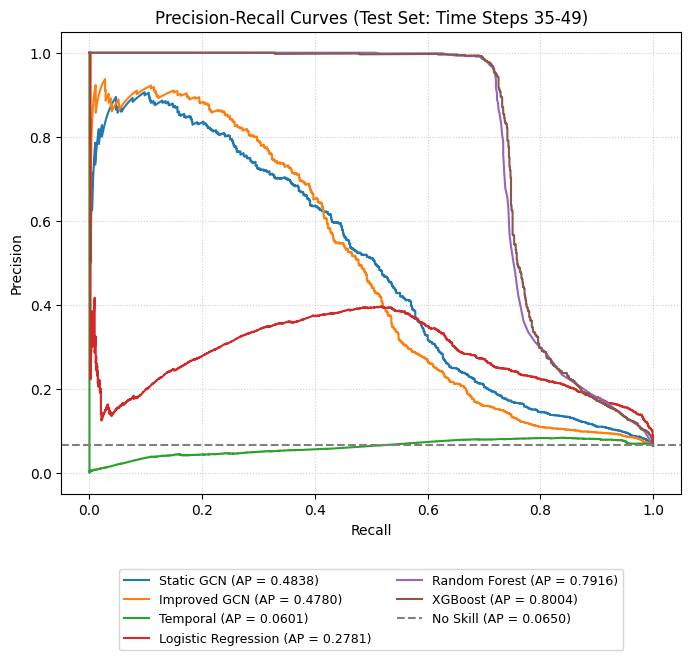

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

# Loop through each model and plot its curve
for name, (y, p) in results.items():
    precision, recall, _ = precision_recall_curve(y, p)
    ap = average_precision_score(y, p)
    plt.plot(recall, precision, label=f"{name} (AP = {ap:.4f})")

# Plot a reference line for random guessing
plt.axhline(y_test.mean(), color='gray', linestyle='--', label=f'No Skill (AP = {y_test.mean():.4f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves (Test Set: Time Steps 35-49)')

# Move the legend outside of the plot box at the bottom to avoid overlapping curves
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9)
plt.grid(True, linestyle=':', alpha=0.6)

# Save the plot to the mounted Google Drive with bbox_inches='tight' to capture the legend
plt.savefig('/content/drive/MyDrive/Elliptic project/pr_curves.png', dpi=300, bbox_inches='tight')
plt.show()

# **for app v2**

In [13]:
import json
import numpy as np
import torch
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

P = '/content/drive/MyDrive/Elliptic project/'
N = data.x.shape[0]
test_np = data.test_mask.numpy()
y_all = data.y.numpy()

# 1) P(illicit) for EVERY node from EVERY model
probs_all = {}
with torch.no_grad():
    model.eval()
    improved_model.eval()
    temporal_model.eval()
    probs_all["static_gcn"] = model(data.x, data.edge_index).exp()[:, 1].numpy()
    probs_all["improved_gcn"] = improved_model(data.x, data.edge_index).exp()[:, 1].numpy()

    # Temporal model works snapshot by snapshot; global_idx maps results back to original node order
    temporal_model.reset()
    tp = np.zeros(N, dtype=np.float32)
    for snap in snapshots:                      # snapshots are in time order 1..49
        out = temporal_model(snap['x'], snap['edge_index'])
        tp[snap['global_idx'].numpy()] = out.exp()[:, 1].numpy()
    probs_all["temporal"] = tp

X_all = data.x.numpy()
probs_all["logreg"] = lr.predict_proba(X_all)[:, 1]
probs_all["random_forest"] = rf.predict_proba(X_all)[:, 1]
probs_all["xgboost"] = xgb_model.predict_proba(X_all)[:, 1]

# 2) Operating thresholds (same ones behind your reported F1 scores)
thr = {
    "static_gcn": 0.5,
    "improved_gcn": float(best_thresh),
    "temporal": float(best_threshold),
    "logreg": 0.5,
    "random_forest": 0.5,
    "xgboost": 0.5
}

# 3) Test-set metrics + downsampled PR curves
yt = y_all[test_np]
metrics, curves = {}, {}
for k, p in probs_all.items():
    pt = p[test_np]
    pred = (pt >= thr[k]).astype(int)
    metrics[k] = dict(
        accuracy=float(accuracy_score(yt, pred)),
        precision=float(precision_score(yt, pred, zero_division=0)),
        recall=float(recall_score(yt, pred, zero_division=0)),
        f1=float(f1_score(yt, pred, zero_division=0)),
        pr_auc=float(average_precision_score(yt, pt)),
        threshold=thr[k]
    )
    pr, rc, _ = precision_recall_curve(yt, pt)
    idx = np.linspace(0, len(pr) - 1, 80).astype(int)
    curves[k] = [[round(float(rc[i]), 4), round(float(pr[i]), 4)] for i in idx]

# 4) Add everything to the existing graph_export.json
export = json.load(open(P + 'graph_export.json'))
for nid in export["nodes"]:
    i = int(nid)
    export["nodes"][nid]["predictions"] = {k: round(float(v[i]), 4) for k, v in probs_all.items()}
export["model_metrics"] = metrics
export["pr_curves"] = curves
export["no_skill"] = float(yt.mean())

json.dump(export, open(P + 'graph_export_v2.json', 'w'))
print("Saved graph_export_v2.json")
for k, m in metrics.items():
    print(f"{k:<14} P={m['precision']:.3f} R={m['recall']:.3f} F1={m['f1']:.3f} PR-AUC={m['pr_auc']:.3f}")

from google.colab import files
files.download(P + 'graph_export_v2.json')


Saved graph_export_v2.json
static_gcn     P=0.394 R=0.572 F1=0.467 PR-AUC=0.484
improved_gcn   P=0.641 R=0.413 F1=0.502 PR-AUC=0.478
temporal       P=0.065 R=1.000 F1=0.122 PR-AUC=0.060
logreg         P=0.192 R=0.872 F1=0.315 PR-AUC=0.278
random_forest  P=0.991 R=0.693 F1=0.815 PR-AUC=0.792
xgboost        P=0.842 R=0.737 F1=0.786 PR-AUC=0.800


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>